Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 82s 68ms/step - accuracy: 0.9221 - loss: 0.2520 - val_accuracy: 0.9808 - val_loss: 0.0601
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 75s 88ms/step - accuracy: 0.9743 - loss: 0.0860 - val_accuracy: 0.9890 - val_loss: 0.0404
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 71s 84ms/step - accuracy: 0.9810 - loss: 0.0641 - val_accuracy: 0.9888 - val_loss: 0.0376
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 59s 57ms/step - accuracy: 0.9839 - loss: 0.0528 - val_accuracy: 0.9908 - val_loss: 0.0359
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 38s 45ms/step - accuracy: 0.9858 - loss: 0.0446 - val_accuracy: 0.9913 - val_loss: 0.0312
313/313 - 5s - 17ms/step - accuracy: 0.9924 - loss: 0.0227
Test loss: 0.022691266611218452
Test accuracy: 0.9923999905586243
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 474ms/step
Sample-1:predicted=7,Actual=2
Sample0:predicted=2,Actual=2
Sample1:predicted=1,Actual=2
Sample2:predicted=0,Actual=2
Sample3:predicted=4,Actual=2
Sample4:predicted=1,Actual=2
Sample5:predicte

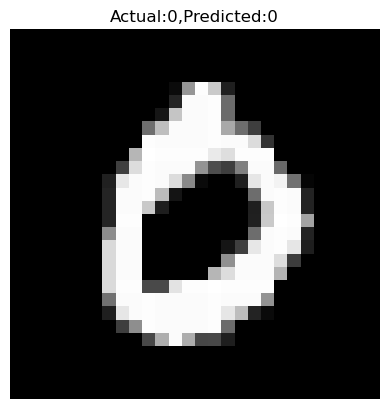

In [3]:
# Handwritten numeric image prediction using CNN for MNIST dataset

import tensorflow as tf
from tensorflow.keras import layers,models
import matplotlib.pyplot as plt
import numpy as np
mnist=tf.keras.datasets.mnist
(x_train,y_train),(x_test,y_test)=mnist.load_data()
x_train=x_train.astype("float32")/255.0
x_test=x_test.astype("float32")/255.0
model=models.Sequential([
layers.Conv2D(32,kernel_size=(3,3),activation="relu",padding="same",input_shape=(28,28,1)),
layers.MaxPooling2D(pool_size=(2,2)),
layers.Conv2D(64,kernel_size=(3,3),activation="relu",padding="same",input_shape=(28,28,1)),
    layers.MaxPooling2D(pool_size=(2,2)),
    layers.Flatten(),
    layers.Dense(128,activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(10,activation="softmax")])
model.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=['accuracy'])
model.summary()
history=model.fit(x_train,y_train,batch_size=64,epochs=5,validation_split=0.1)
test_loss,test_acc=model.evaluate(x_test,y_test,verbose=2)
print("Test loss:",test_loss)
print("Test accuracy:",test_acc)
predictions=model.predict(x_test[:11])
for i in range(11):
    predicted_label=np.argmax(predictions[i])
    actual_tabel=y_test[1]
    print(f"Sample{i-1}:predicted={predicted_label},Actual={actual_tabel}")
plt.imshow(x_test[3].squeeze(),cmap="gray")
plt.title(f"Actual:{y_test[3]},Predicted:{predicted_label}")
plt.axis("off")
plt.show()
